In [1]:
import pandas as pd
from src.ingestion import load_retail_data
from src.cleaning import cleaned_data
import matplotlib.pyplot as plt

In [2]:
data = load_retail_data("data/raw")

clean_data = cleaned_data(data)

In [3]:
train = clean_data["train"]

print(train["sales"].describe())

print("\nZero-sales rows:", (train["sales"] == 0).sum())
print(
    "Percentage of zero-sales rows:",
    round((train["sales"] == 0).mean() * 100, 2),
    "%"
)

count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64

Zero-sales rows: 939130
Percentage of zero-sales rows: 31.3 %


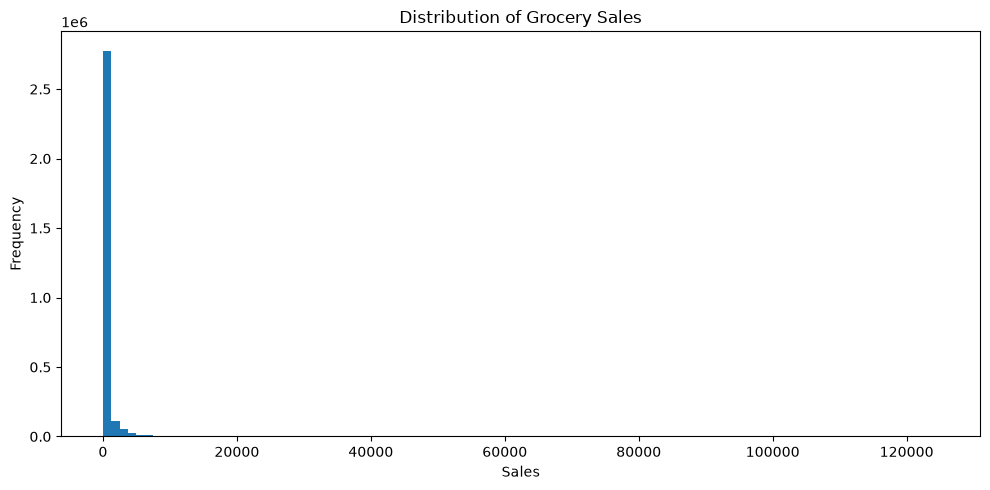

In [4]:
plt.figure(figsize=(10, 5))
plt.hist(train["sales"], bins=100)
plt.title("Distribution of Grocery Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [5]:
sales_99th = train["sales"].quantile(0.99)

print("99th percentile:", sales_99th)
print("Percentage of rows at or below it:",
      round((train["sales"] <= sales_99th).mean() * 100, 2), "%")

99th percentile: 5507.0
Percentage of rows at or below it: 99.0 %


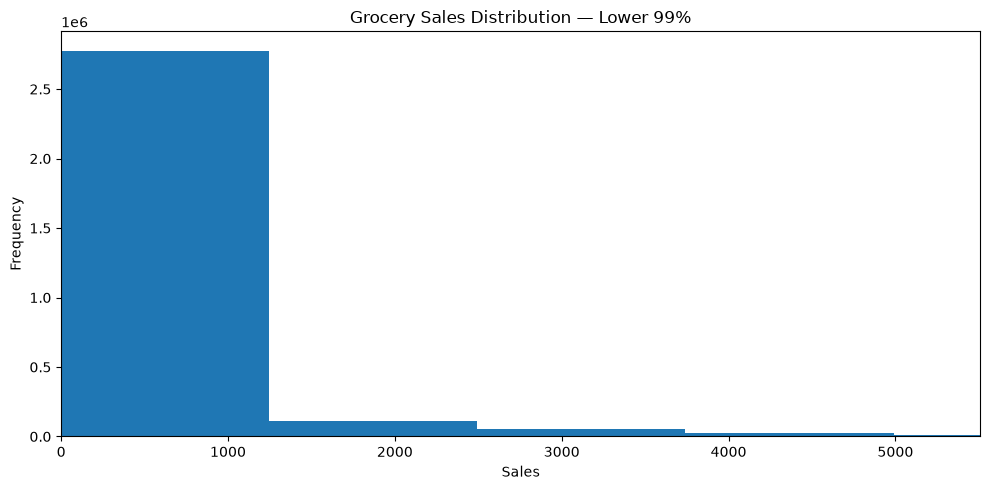

In [6]:
plt.figure(figsize=(10, 5))
plt.hist(train["sales"], bins=100)
plt.xlim(0, sales_99th)
plt.title("Grocery Sales Distribution — Lower 99%")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [7]:

daily_sales = (
    train.groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
)

print(daily_sales.head())
print("\nNumber of unique dates:", daily_sales["date"].nunique())
print("\nDaily sales statistics:")
print(daily_sales["sales"].describe())

        date          sales
0 2013-01-01    2511.618999
1 2013-01-02  496092.417944
2 2013-01-03  361461.231124
3 2013-01-04  354459.677093
4 2013-01-05  477350.121229

Number of unique dates: 1684

Daily sales statistics:
count    1.684000e+03
mean     6.375564e+05
std      2.344102e+05
min      2.511619e+03
25%      4.427115e+05
50%      6.321889e+05
75%      7.859455e+05
max      1.463084e+06
Name: sales, dtype: float64


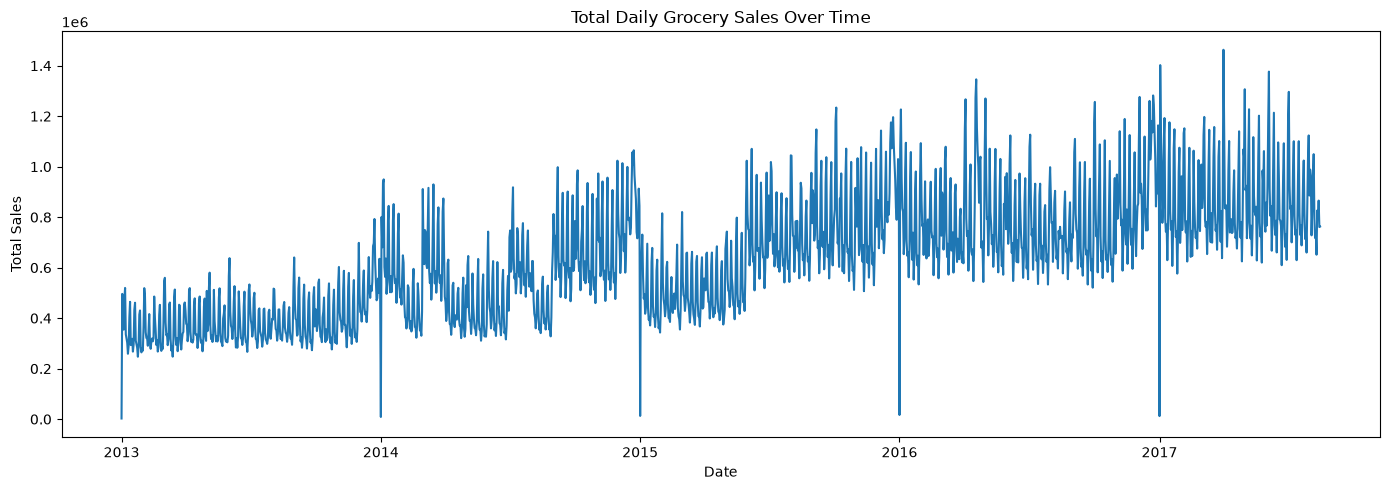

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales["date"], daily_sales["sales"])
plt.title("Total Daily Grocery Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [9]:
from src.ingestion import load_retail_data
from src.cleaning import cleaned_data

In [10]:
data = load_retail_data("data/raw")
clean_data = cleaned_data(data)

In [11]:
df = clean_data["train"].copy()

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 137.4 MB


In [13]:
df = df.merge(clean_data["oil"], on="date", how="left")

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 7 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
 6   dcoilwtico   float64       
dtypes: datetime64[us](1), float64(2), int64(3), str(1)
memory usage: 160.3 MB


In [15]:
holi_df = clean_data["holidays_events"].copy()

In [16]:
holi_df.head()

,date,event_count,has_holiday,has_event,has_additional,has_transfer,has_bridge,has_workday,is_national,is_regional,is_local
0,2012-03-02,1,True,False,False,False,False,False,False,False,True
1,2012-04-01,1,True,False,False,False,False,False,False,True,False
2,2012-04-12,1,True,False,False,False,False,False,False,False,True
3,2012-04-14,1,True,False,False,False,False,False,False,False,True
4,2012-04-21,1,True,False,False,False,False,False,False,False,True


In [17]:
for col in holi_df.columns:
    print(f"{col}: {holi_df[col].nunique()} unique values")

date: 312 unique values
event_count: 4 unique values
has_holiday: 2 unique values
has_event: 2 unique values
has_additional: 2 unique values
has_transfer: 2 unique values
has_bridge: 2 unique values
has_workday: 2 unique values
is_national: 2 unique values
is_regional: 2 unique values
is_local: 2 unique values


In [19]:
clean_data["holidays_events"].head()

,date,event_count,has_holiday,has_event,has_additional,has_transfer,has_bridge,has_workday,is_national,is_regional,is_local
0,2012-03-02,1,True,False,False,False,False,False,False,False,True
1,2012-04-01,1,True,False,False,False,False,False,False,True,False
2,2012-04-12,1,True,False,False,False,False,False,False,False,True
3,2012-04-14,1,True,False,False,False,False,False,False,False,True
4,2012-04-21,1,True,False,False,False,False,False,False,False,True


In [ ]:
holiday_num_col = ['event_count']
holiday_bool_cols = ['has_holiday', 'has_event', 'has_additional', 'has_transfer', 'has_bridge', 'has_workday']

df[holiday_num_col] = df[holiday_num_col].fillna(0)
df[holiday_bool_cols] = df[holiday_bool_cols].fillna(False)

In [ ]:
df["dcoilwtico"] = df["dcoilwtico"].ffill()

In [ ]:
locale_bool_cols = ['is_local', 'is_regional', 'is_national']

df[locale_bool_cols] = df[locale_bool_cols].fillna(False)